# 09. Make one experience work across devices

Use platform files, readable glass, flexible language, and explicit voice cleanup without promising identical capabilities.

**60 minutes including practice · Canopy**

This is a **Python 3 notebook**. It contains the complete lesson, embedded vector illustrations, React Native examples for reading, and executable Python models. Python does not run React Native. Run the `.tsx` exercise in Expo using the workbook instructions. No cloud credentials or live services are needed for the notebook.

Run the cells from top to bottom. Change a control, make a prediction, then explain the result. If widgets are unavailable, edit a model's default arguments and rerun its cell.

If you have the complete course folder, [open the interactive guide](../index.html#lesson-09) or [read the exercise instructions](../exercises/README.md). These companion links are absent in a notebooks-only or single-lesson download; the notebook itself still runs independently.


## What you will be able to do

- You can choose a small platform check or a separate platform file for the right reason.
- You can explain why an opaque surface is a valid glass fallback.
- You can trace microphone, connection, playback, and cleanup states without confusing them with one loading flag.

## Before you begin

You can explain owner-scoped resources and durable native drafts.

You can build an accessible component with props and state.


In [1]:
from IPython.display import display, HTML, SVG
import json
import os
import inspect

# Widgets are optional. Without them, edit parameters and rerun the model cell.
try:
    if os.environ.get('PLANTOPEDIA_NO_WIDGETS') == '1':
        raise ImportError('Widget-free verification mode')
    import ipywidgets as widgets
except ImportError:
    widgets = None

def explore(function, **controls):
    if widgets is not None:
        display(widgets.interactive(function, **controls))
    else:
        print('Optional controls are unavailable. Edit the explorer function defaults and rerun this model cell.')
        defaults = {name: parameter.default for name, parameter in inspect.signature(function).parameters.items()}
        print('Using function defaults:', defaults)
        function()

print('Python teaching model ready. React Native TSX runs separately in Expo.')


Python teaching model ready. React Native TSX runs separately in Expo.


Cross-platform work aims to preserve the person's task while adapting to the device. A person should be able to find a plant, read its notes, and understand a save failure on a phone or in a browser. That does not mean every platform uses the same storage, native visual effect, or audio implementation. Good shared code makes those differences explicit behind a small, dependable interface.

Plantopedia already demonstrates this pattern. It imports GlassSurface without naming a platform, while the bundler chooses the iOS, browser, or default implementation. Audio and photo helpers use similar boundaries. This lesson connects those code choices to readable design, translated text, and a voice experience that releases the microphone when its session ends.


## Share a contract and vary the implementation

Use Platform.OS for a small local difference, such as a platform-specific explanation. When the entire implementation differs, a separate file is easier to read and test. In this repository, GlassSurface.ios.tsx uses the native glass API when suitable, GlassSurface.web.tsx uses browser capabilities, and GlassSurface.tsx provides a regular surface. Callers keep one import and the same ViewProps-shaped interface.

The teaching default surface below is intentionally simple and fully opaque. Put platform variants beside it only when you have a concrete need. A .web.tsx implementation can contain browser-only CSS capability checks; those checks should not leak into the native component. A shared import does not imply that every platform file has identical internals or lifetime guarantees.

The same reasoning explains storage and audio boundaries. A browser preview can help test screen flow while a native module handles continuous microphone frames. Name those limits in the product and in your acceptance evidence. A simulated permission button in this course cannot prove that an iOS microphone session releases correctly.


**Teaching example: StudySurface.tsx**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```tsx
import { StyleSheet, View, type ViewProps } from 'react-native';

export function StudySurface({ style, ...props }: ViewProps) {
  return <View {...props} style={[styles.surface, style]} />;
}
const styles = StyleSheet.create({
  surface: {
    backgroundColor: '#FFFFFF', borderColor: '#B8D4CC',
    borderWidth: 1, borderRadius: 24, padding: 20, gap: 12,
  },
});
// StudySurface.ios.tsx and StudySurface.web.tsx can later
// export the same component API with different implementations.
// Callers keep: import { StudySurface } from './StudySurface';
```


## Make glass support reading instead of competing with it

A vivid background can make an interface feel alive, but text needs a stable reading surface. A translucent card may look clear over one illustration and become difficult over another. Place strong text on a sufficiently solid surface, use generous spacing, and keep the most important action visually distinct. Decorative color should help orientation without becoming the only way to recognize a failure or selection.

Plantopedia's iOS implementation begins conservatively with reduced transparency enabled, reads the system preference, listens for changes, and falls back to a regular View when transparency should be reduced or a glass capability is unavailable. Its browser implementation also checks contrast preference and backdrop-filter support. The default implementation remains a regular View. These are deliberate ways to preserve the task, not an incomplete version of the experience.

Treat motion similarly. Animation may explain a transition, but it should not be necessary to understand a status. Respect reduced-motion preferences, allow a static illustration, and keep progress text available. This course uses vector graphics because they stay sharp at different sizes, while its diagrams still need text descriptions and a sensible reading order. Test the smallest layout, enlarged text, keyboard focus, and light and dark surfaces before adding more blur.


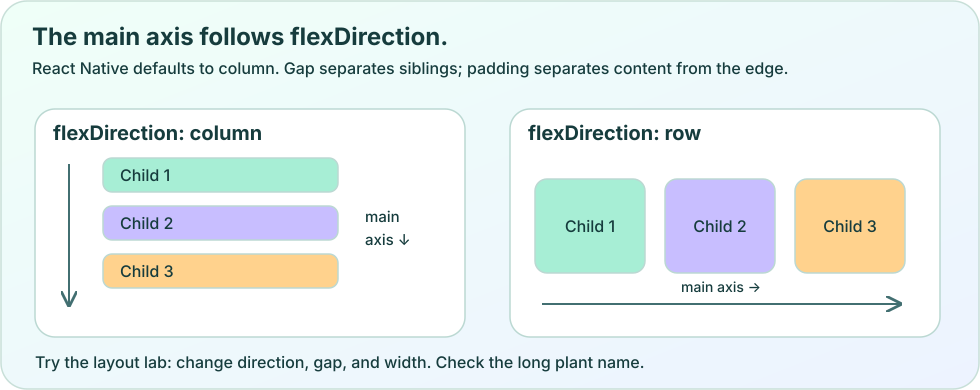

In [2]:
# Embedded original vector illustration; no external image files are required.
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" width="980" height="390" viewBox="0 0 980 390" role="img" aria-labelledby="title desc"><title id="title">Flexbox main axes</title><desc id="desc">Two containers compare a column with a vertical main axis and a row with a horizontal main axis. Three children retain their order. A narrow screen still needs readable text.</desc><defs>\n<linearGradient id="bg" x2="1" y2="1"><stop stop-color="#effff8"/><stop offset="1" stop-color="#edf3ff"/></linearGradient>\n<linearGradient id="leaf" x2="1" y2="1"><stop stop-color="#37e6b0"/><stop offset="1" stop-color="#07886c"/></linearGradient>\n<linearGradient id="glass" x2="1" y2="1"><stop stop-color="#fff" stop-opacity=".94"/><stop offset="1" stop-color="#e2efff" stop-opacity=".72"/></linearGradient>\n<linearGradient id="violet" x2="1" y2="1"><stop stop-color="#a58cff"/><stop offset="1" stop-color="#6550d9"/></linearGradient>\n<marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0 0L8 4L0 8" fill="none" stroke="#426f71" stroke-width="1.4"/></marker>\n</defs><g font-family="system-ui,-apple-system,Segoe UI,sans-serif"><rect x="1" y="1" width="978" height="388" rx="26" fill="url(#bg)" stroke="#c8dfd8" stroke-width="1.5"/><text x="32" y="45" font-size="24" fill="#163c3d" font-weight="750" text-anchor="start">The main axis follows flexDirection.</text><text x="32" y="74" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">React Native defaults to column. Gap separates siblings; padding separates content from the edge.</text><rect x="35" y="109" width="430" height="228" rx="20" fill="#fff" stroke="#bbd8d2" stroke-width="1.5"/><text x="53" y="140" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">flexDirection: column</text><rect x="103" y="158" width="235" height="34" rx="9" fill="#a7eed5" stroke="#bbd8d2" stroke-width="1.5"/><text x="120" y="181" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Child 1</text><rect x="103" y="206" width="235" height="34" rx="9" fill="#c8beff" stroke="#bbd8d2" stroke-width="1.5"/><text x="120" y="229" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Child 2</text><rect x="103" y="254" width="235" height="34" rx="9" fill="#ffd28d" stroke="#bbd8d2" stroke-width="1.5"/><text x="120" y="277" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Child 3</text><path d="M69 164L69 305" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><text x="365" y="222" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">main</text><text x="365" y="245" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">axis ↓</text><rect x="510" y="109" width="430" height="228" rx="20" fill="#fff" stroke="#bbd8d2" stroke-width="1.5"/><text x="528" y="140" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">flexDirection: row</text><rect x="535" y="179" width="110" height="94" rx="12" fill="#a7eed5" stroke="#bbd8d2" stroke-width="1.5"/><text x="590" y="232" font-size="16" fill="#163c3d" font-weight="500" text-anchor="middle">Child 1</text><rect x="665" y="179" width="110" height="94" rx="12" fill="#c8beff" stroke="#bbd8d2" stroke-width="1.5"/><text x="720" y="232" font-size="16" fill="#163c3d" font-weight="500" text-anchor="middle">Child 2</text><rect x="795" y="179" width="110" height="94" rx="12" fill="#ffd28d" stroke="#bbd8d2" stroke-width="1.5"/><text x="850" y="232" font-size="16" fill="#163c3d" font-weight="500" text-anchor="middle">Child 3</text><path d="M542 304L900 304" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><text x="721.0" y="292.0" font-size="14" fill="#163c3d" font-weight="500" text-anchor="middle">main axis →</text><text x="35" y="368" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Try the layout lab: change direction, gap, and width. Check the long plant name.</text></g></svg>'))


> **A fallback must keep the task intact**
>
> When glass is unavailable or reduced transparency is requested, the person should still see the same content and actions on a readable surface. Visual parity is less important than task continuity.


## Let language and text size change the layout

A translated action can be much longer than its English version. Fixed-height text boxes and narrow icon-only actions can therefore fail even on a screen that looked balanced during initial design. Allow text to wrap, let rows grow, and use minimum touch sizes rather than assuming one short label. Test a large font scale together with a narrow screen, because these conditions interact.

Plantopedia's preferences provider resolves Light, Dark, or System appearance and exposes a translation function for seven dictionaries. Components ask for a message key instead of scattering duplicated English strings through the interface. The following provider-dependent excerpt uses existing message keys. Notice that its action has an explicit role and label, its text is allowed to grow, and the colors come from the resolved theme.

Do not translate an arbitrary error code by displaying it directly as prose. Map expected codes to useful local messages and an action, while preserving a safe code for diagnosis. Likewise, a species' scientific name and a person's chosen nickname have different translation rules from interface copy. Keep specimen identity stable while presentation language changes.


**Provider-dependent teaching excerpt: GardenInvitation.tsx**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```tsx
import { Pressable, Text, View } from 'react-native';
import { useRouter } from 'expo-router';
import { usePreferences } from '../theme/preferences';

export function GardenInvitation() {
  const { colors, t } = usePreferences();
  const router = useRouter();
  return <View style={{ gap: 12, padding: 20, backgroundColor: colors.surface }}>
    <Text style={{ color: colors.text, fontSize: 24, fontWeight: '700' }}>
      {t('myGarden')}
    </Text>
    <Pressable accessibilityRole="button" accessibilityLabel={t('scan')}
      onPress={() => router.push('/scan')}
      style={{ minHeight: 48, padding: 14, borderRadius: 16,
        justifyContent: 'center', backgroundColor: colors.primary }}>
      <Text style={{ color: colors.onPrimary, fontSize: 17 }}>{t('scan')}</Text>
    </Pressable>
  </View>;
}
```


## Voice is a resource lifecycle, not a single spinner

Continuous voice involves permission, hardware, a server connection, microphone input, received captions, queued playback, and interruptions. A single busy flag cannot explain whether the app is waiting for permission, listening, processing, or playing. Plantopedia's voice state describes these phases and also tracks facts such as muted and playingAudio. The interface can therefore give a useful action at each point.

The default session controller creates a live voice transport for an owner. Its native audio factory looks for the local PlantopediaVoice module, requests microphone permission, and subscribes to audio, played, and failure events. Expo Go does not contain that custom native bridge, so continuous native voice requires a development build that includes it. Reinstalling JavaScript dependencies or refreshing Metro does not add native code to an already installed binary.

Connection setup and playback can finish after a person presses End. The transport uses a generation counter to distinguish the current run from an old one. Cleanup advances that counter, detaches socket handlers, closes the socket, clears timers and queued audio, and disposes the audio resource. A late event from the old run must not revive the microphone or publish a stale caption into a new session.


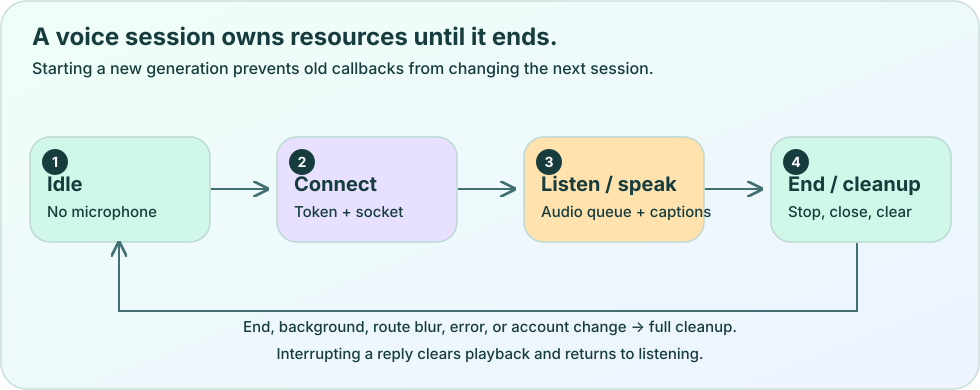

In [3]:
# Embedded original vector illustration; no external image files are required.
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" width="980" height="390" viewBox="0 0 980 390" role="img" aria-labelledby="title desc"><title id="title">Voice session lifecycle</title><desc id="desc">Idle transitions to connection, then listening and speaking. Ending cleans up audio, sockets and timers before returning to idle. Late callbacks must not update a new session.</desc><defs>\n<linearGradient id="bg" x2="1" y2="1"><stop stop-color="#effff8"/><stop offset="1" stop-color="#edf3ff"/></linearGradient>\n<linearGradient id="leaf" x2="1" y2="1"><stop stop-color="#37e6b0"/><stop offset="1" stop-color="#07886c"/></linearGradient>\n<linearGradient id="glass" x2="1" y2="1"><stop stop-color="#fff" stop-opacity=".94"/><stop offset="1" stop-color="#e2efff" stop-opacity=".72"/></linearGradient>\n<linearGradient id="violet" x2="1" y2="1"><stop stop-color="#a58cff"/><stop offset="1" stop-color="#6550d9"/></linearGradient>\n<marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0 0L8 4L0 8" fill="none" stroke="#426f71" stroke-width="1.4"/></marker>\n</defs><g font-family="system-ui,-apple-system,Segoe UI,sans-serif"><rect x="1" y="1" width="978" height="388" rx="26" fill="url(#bg)" stroke="#c8dfd8" stroke-width="1.5"/><text x="32" y="45" font-size="24" fill="#163c3d" font-weight="750" text-anchor="start">A voice session owns resources until it ends.</text><text x="32" y="74" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Starting a new generation prevents old callbacks from changing the next session.</text><rect x="30" y="137" width="180" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="55" cy="162" r="13" fill="#163c3d"/><text x="55" y="167" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">1</text><text x="47" y="191" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Idle</text><text x="47" y="217" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">No microphone</text><rect x="277" y="137" width="180" height="105" rx="20" fill="#e7e0ff" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="302" cy="162" r="13" fill="#163c3d"/><text x="302" y="167" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">2</text><text x="294" y="191" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Connect</text><text x="294" y="217" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">Token + socket</text><rect x="524" y="137" width="180" height="105" rx="20" fill="#ffe2ad" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="549" cy="162" r="13" fill="#163c3d"/><text x="549" y="167" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">3</text><text x="541" y="191" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Listen / speak</text><text x="541" y="217" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">Audio queue + captions</text><rect x="771" y="137" width="180" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="796" cy="162" r="13" fill="#163c3d"/><text x="796" y="167" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">4</text><text x="788" y="191" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">End / cleanup</text><text x="788" y="217" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">Stop, close, clear</text><path d="M211 189L267 189" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><path d="M458 189L514 189" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><path d="M705 189L761 189" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><path d="M857 243V311H119V243" fill="none" stroke="#426f71" stroke-width="2" marker-end="url(#arrow)"/><text x="490" y="332" font-size="15" fill="#163c3d" font-weight="500" text-anchor="middle">End, background, route blur, error, or account change → full cleanup.</text><text x="490" y="359" font-size="15" fill="#163c3d" font-weight="500" text-anchor="middle">Interrupting a reply clears playback and returns to listening.</text></g></svg>'))


## Choose the owner of cleanup carefully

A controller can outlive a dock even though its active connection ends when the route loses focus. Plantopedia keeps one owner-scoped voice controller in the session so individual route components do not each create a competing microphone. VoiceDock explicitly disconnects that connection during route-focus cleanup. Its cloud session also disconnects when the app becomes inactive and releases resources on cleanup. Signing out must release owner resources too. Read the existing ownership path before adding another useEffect that starts audio automatically.

The teaching hook below shows only the cleanup idea for an injected resource. It neither starts recording nor replaces the production SessionProvider. Its dependency must be stable; if a caller creates a new object every render, cleanup will repeatedly disconnect it. The onFailure callback should be stable too. The production transport performs its own detailed teardown and stale-event checks.

Captions and a text interaction path should remain useful when audio playback is blocked or the microphone is denied. Test denial, repeated start/end taps, backgrounding, disconnect during playback, and an account change. The lab demonstrates the state decisions with synthetic events; it cannot establish acoustic quality, interruption sensitivity, or actual native hardware release.


**Teaching excerpt: useVoiceCleanup.ts**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```tsx
import { useEffect } from 'react';
import { AppState } from 'react-native';

type Resource = { disconnect(): Promise<void> };
export function useVoiceCleanup(
  resource: Resource, onFailure: (error: unknown) => void,
) {
  useEffect(() => {
    const stop = () => { void resource.disconnect().catch(onFailure); };
    const subscription = AppState.addEventListener('change', state => {
      if (state !== 'active') stop();
    });
    return () => { subscription.remove(); stop(); };
  }, [resource, onFailure]);
}
```


## Experiment: predict, change, explain

Choose a platform, support flag, transparency preference, and example language to inspect the surface decision and label. Defaults are iOS, unsupported glass, normal transparency, and English. The voice example below is a separate editable sequence: change the start/end/receive calls, save each returned generation, and predict which callback is ignored. It has no interruption or audio controls. Use the browser session model and a real-device run for those additional boundaries.

The cell below is a bounded Python analogy of the lesson. Its fixtures do not call the app API, request permission, or certify device behavior. Its assertions check the stated model only.


In [4]:
def surface(platform='ios', supported=False, reduce_transparency=False):
    if platform == 'ios' and supported and not reduce_transparency:
        return 'Native glass after both API and OS checks'
    return 'Opaque accessible fallback'

def explore_platform(platform='ios', supported=False, reduce_transparency=False, language='en'):
    print(surface(platform, supported, reduce_transparency))
    labels = {'en': 'Save discovery', 'de': 'Entdeckung speichern', 'ja': '発見を保存'}
    print('Label:', labels[language]); print('Allow wrapping and test actual font scaling.')
    print('Web CSS blur is a separate adapter, not native glass.')

explore(explore_platform, platform=['ios', 'android', 'web'], supported=False, reduce_transparency=False, language=['en', 'de', 'ja'])

class VoiceModel:
    def __init__(self):
        self.generation = 0; self.phase = 'idle'; self.resources = set()
    def start(self):
        self.end()
        self.phase = 'connecting'; self.resources = {'socket', 'timer', 'microphone'}
        return self.generation
    def receive(self, generation):
        if generation != self.generation or self.phase == 'idle':
            return 'ignored stale callback'
        self.phase = 'ready'; return 'current session ready'
    def end(self):
        self.generation += 1; self.phase = 'idle'; self.resources.clear()

v = VoiceModel(); first = v.start(); v.end(); second = v.start()
assert v.receive(first) == 'ignored stale callback'
assert v.receive(second) == 'current session ready'
v.end()
assert not v.resources and v.phase == 'idle'
assert surface('ios', True, True) == 'Opaque accessible fallback'
print('Lifecycle model checks passed. Real microphone release still needs device acceptance.')


interactive(children=(Dropdown(description='platform', options=('ios', 'android', 'web'), value='ios'), Checkb…

Lifecycle model checks passed. Real microphone release still needs device acceptance.


## Make a prediction of your own

Should supported iOS glass be used when reduced transparency is requested?

Replace `None` below. A blank answer reports **not attempted**; it is never counted as passing. The check gives feedback without interrupting “Run All.”


In [5]:
your_answer = None  # Replace with surface('ios', True, True).
if your_answer is None:
    print('Not attempted. Replace None, then rerun this cell.')
elif your_answer == 'Opaque accessible fallback':
    print('Correct. '+'The accessibility preference takes precedence over the decorative effect.')
else:
    print('Revisit your prediction. '+'The accessibility preference takes precedence over the decorative effect.')


Not attempted. Replace None, then rerun this cell.


## Retrieve the ideas

**1. When native glass is unavailable or reduced transparency is enabled, what should happen?**

1. Hide the content that normally sits on glass.
2. Keep the same task available on a readable opaque surface.
3. Force blur because visual consistency is more important.

**2. Why can Expo Go preview screens but fail continuous native voice in this app?**

1. Expo Go cannot render Text components.
2. A .tsx file always requires Xcode.
3. Its installed native binary does not include the custom PlantopediaVoice bridge.

**3. An old socket event arrives after End and a new Start. What should prevent it from updating the new session?**

1. A run identity or generation check that recognizes the event as stale.
2. The button's visual opacity.
3. Changing the plant nickname.

Set each value in the next cell to your selected option number, starting at 1. You can change it and rerun for more feedback.


In [6]:
quiz = [{'question': 'When native glass is unavailable or reduced transparency is enabled, what should happen?', 'options': ['Hide the content that normally sits on glass.', 'Keep the same task available on a readable opaque surface.', 'Force blur because visual consistency is more important.'], 'answer': 1, 'explanation': "The surface is there to support the person's task. A readable regular View preserves content and actions across capabilities and accessibility preferences. Hiding content or forcing transparency would undermine that purpose."}, {'question': 'Why can Expo Go preview screens but fail continuous native voice in this app?', 'options': ['Expo Go cannot render Text components.', 'A .tsx file always requires Xcode.', 'Its installed native binary does not include the custom PlantopediaVoice bridge.'], 'answer': 2, 'explanation': 'JavaScript can only call native modules present in the installed binary. A matching development build includes the custom bridge. Refreshing JavaScript does not insert native code into Expo Go.'}, {'question': 'An old socket event arrives after End and a new Start. What should prevent it from updating the new session?', 'options': ['A run identity or generation check that recognizes the event as stale.', "The button's visual opacity.", 'Changing the plant nickname.'], 'answer': 0, 'explanation': 'Asynchronous events can outlive the action that created them. A generation check ties each event to the current run. Visual styling and unrelated record data do not establish that lifecycle relationship.'}]
answers = [None, None, None]  # Replace None with 1, 2, or 3.
correct = 0
for number, (question, answer) in enumerate(zip(quiz, answers), 1):
    if answer is None:
        print(f'{number}. Not attempted.')
    elif type(answer) is not int or answer not in range(1, len(question['options']) + 1):
        print(f'{number}. Choose a valid option number.')
    else:
        right = answer - 1 == question['answer']
        correct += int(right)
        print(f"{number}. {'Correct' if right else 'Revisit this idea'}. {question['explanation']}")
print(f'{correct} of {len(quiz)} correct; unanswered questions do not count as passing.')


1. Not attempted.
2. Not attempted.
3. Not attempted.
0 of 3 correct; unanswered questions do not count as passing.


## Build in Expo: Run a cross-platform continuity review

Review one plant card and one voice flow across visual, language, and resource boundaries. Record observed behavior separately from simulated behavior.

1. List the shared import and selected implementation for GlassSurface on iOS, web, and the default native path.
2. Render a card with enlarged text and long translated labels; explain any clipping and adjust the teaching layout to grow.
3. Compare a vivid translucent surface with a solid surface and verify that status remains understandable without color or motion alone.
4. Draw start → permission → connecting → listening → playback/interrupt → end, including a denial path and a late-event path.
5. Write a device checklist for denied microphone permission, backgrounding, disconnect during playback, and signing out.

### Check your result

- [ ] Each platform preserves the main task even when a visual or audio capability is unavailable.
- [ ] The card can wrap long labels without shrinking the touch action below its intended minimum.
- [ ] Your voice trace names the resource owner and the point that invalidates stale events.
- [ ] Your evidence explicitly distinguishes browser models from native hardware acceptance.

Download the matching exercise bundle from the HTML course, or use the `exercises` folder if you downloaded the complete course. A notebooks-only download does not include that folder. Files under `docs/tutorials` do not become Expo routes until copied as instructed. The numbered workbook supplies a related concrete practice task; the inline exercise can ask you to extend it.


<details><summary>Hint</summary>

Follow resource creation to its matching disposal. For visual testing, combine narrow width, long text, and large font size instead of testing each only in isolation.

</details>

<details><summary>Worked reasoning / solution</summary>

```text
Keep a shared component API and let platform files vary its internals. Use an opaque readable fallback when glass is unavailable or reduced transparency is requested. Let text wrap and resolve copy through the preferences provider. Keep the live transport in the owner-scoped session, disconnect and dispose its audio/socket resources at the appropriate lifecycle boundary, and ignore events from previous generations. A diagram or mocked test supports the state logic, while a development build on a physical device supplies the remaining camera/audio evidence.
```

</details>


## Explain it in your own words

If the browser can display the same voice dock as iOS, which facts still need separate verification before you claim equal voice support? Explain implementation selection, permission, playback, and cleanup.

*Write your explanation in the Markdown cell below. Save the notebook to keep your work.*


My explanation:

<!-- Replace this comment with a connected explanation and an example. -->


## Find this idea in the app

- [src/theme/GlassSurface.ios.tsx](../../../src/theme/GlassSurface.ios.tsx) — The iOS surface checks glass capability and reduced-transparency preference.

- [src/theme/GlassSurface.web.tsx](../../../src/theme/GlassSurface.web.tsx) — Browser appearance checks contrast, transparency, and backdrop-filter support.

- [src/theme/preferences.tsx](../../../src/theme/preferences.tsx) — The app resolves theme and message dictionaries through one provider.

- [src/services/voice-session.ts](../../../src/services/voice-session.ts) — One owner-scoped voice controller survives individual dock and route components.

- [src/platform/live-voice.ts](../../../src/platform/live-voice.ts) — The transport coordinates socket/audio state and invalidates stale runs during cleanup.

- [src/platform/stream-audio.ts](../../../src/platform/stream-audio.ts) — The native implementation requires the custom bridge and disposes listeners and hardware.

Repository links require this notebook to remain in the checkout’s `docs/tutorials/notebooks` folder. Downloaded notebooks still contain every explanation and embedded diagram.

## Primary documentation

- [React Native 0.86: platform-specific code](https://reactnative.dev/docs/0.86/platform-specific-code)
- [React Native 0.86: accessibility](https://reactnative.dev/docs/0.86/accessibility)
- [Expo SDK 57: GlassEffect](https://docs.expo.dev/versions/v57.0.0/sdk/glass-effect/)
- [Expo: introduction to development builds](https://docs.expo.dev/develop/development-builds/introduction/)


## Carry these ideas forward

- Cross-platform design shares task contracts while allowing implementation differences.
- Readable opaque surfaces, flexible text, and static feedback are complete accessibility choices.
- Voice sessions need a stable owner, detailed states, stale-event protection, and explicit resource release.
